# **Projeto Integrador II - Terra Signal**

### **Integrantes:** 
- Giovanna Coelho Gilio de Sá
- Enzo Preite Fontes
- Rodrigo Freitas Pereira

---
**Base:** `history.csv` - 5.634 registros e 23 variáveis.  
**Objetivo:** estruturar os dados nas camadas Bronze, Silver e Gold e investigar características associadas ao cancelamento de clientes da Terra Signal.

### Perguntas de negócio
1. Qual é a proporção de clientes que cancelaram e quais características de perfil aparecem com maior frequência nesse grupo?
2. Como a taxa de cancelamento varia conforme o contrato, o tempo de relacionamento e os serviços contratados?
3. Existe associação entre mensalidade, renda mensal, comprometimento da renda e cancelamento?
4. Quais métodos de pagamento e modalidades de internet apresentam maiores taxas de cancelamento?
5. Quais ações a Terra Signal pode investigar ou testar para reduzir o churn?

### Arquitetura Medalhão
| Camada | Conteúdo | Regra deste projeto |
|---|---|---|
| **Bronze** | Dados recebidos de `history.csv` | Leitura e diagnóstico. Não alterar os dados originais. |
| **Silver** | Dados limpos e padronizados | Corrigir tipos e categorias; tratar somente situações justificáveis; documentar ausências remanescentes. |
| **Gold** | Dados analíticos | Criar indicadores e tabelas agregadas para responder às perguntas de negócio. |

A análise é exploratória. Diferenças entre grupos indicam **associações**, não comprovam que uma variável cause o cancelamento.

## 1. Importações e configurações

Bibliotecas utilizadas: `pandas` e `numpy` para manipulação; `plotly` para gráficos interativos; `matplotlib` e `wordcloud` para a análise complementar dos comentários.

In [2]:
%pip install pandas numpy plotly matplotlib wordcloud nbformat
%pip install --upgrade pip

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [28]:
from pathlib import Path
import numpy as np
import pandas as pd
from wordcloud import STOPWORDS, WordCloud
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display, Markdown ### Deixa com formato de tabela

## 2. Camada Bronze - leitura e diagnóstico dos dados originais

Nesta etapa, foi realizada a extração dos dados brutos a partir do arquivo CSV original (`history.csv`).  
O objetivo é carregar os dados em memória exatamente como foram gerados pela fonte, permitindo uma inspeção inicial da volumetria (linhas e colunas) e do formato das informações.

In [4]:
# Leitura do CSV
df_bronze = pd.read_csv('history.csv', encoding="utf-8", sep=",")

print("Dimensão da camada Bronze:", df_bronze.shape)
df_bronze.head()
df_bronze.tail()

Dimensão da camada Bronze: (5634, 23)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,CustomerFeedback,MonthlyIncome
5629,8909-BOLNL,Male,0,No,No,3,Yes,No,No,No internet service,...,No internet service,No internet service,One year,No,Mailed check,21.20,52.05,No,I have been a customer with this company for 3...,8354
5630,2832-KJCRD,Female,0,No,No,38,Yes,Yes,Fiber optic,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,103.65,3988.50,No,I have been a customer with this company for 3...,9308
5631,7975-JMZNT,Male,0,Yes,No,66,Yes,Yes,DSL,Yes,...,Yes,Yes,Two year,No,Bank transfer (automatic),91.70,6075.90,No,I have been a customer with this DSL internet ...,2113
5632,4250-ZBWLV,Male,0,No,No,68,Yes,Yes,Fiber optic,No,...,Yes,Yes,One year,No,Electronic check,108.45,7176.55,Yes,I have been a customer with this company for o...,3904
5633,3915-ODIYG,Male,1,No,No,60,Yes,Yes,DSL,Yes,...,No,Yes,One year,Yes,Electronic check,71.75,4374.55,No,I have been a loyal customer of this internet ...,3016


In [5]:
# Verificar os valores existentes na coluna tenure
print(df_bronze["tenure"].value_counts(dropna=False).tail(10))

# Verificar especificamente se existe o texto "unknown"
print(
    "Quantidade de 'unknown':",
    (df_bronze["tenure"].astype("string").str.strip().str.lower() == "unknown").sum()
)

tenure
50         49
45         49
59         48
38         47
28         43
44         41
36         39
39         37
unknown    19
0          10
Name: count, dtype: int64
Quantidade de 'unknown': 19


In [6]:
# Estrutura e tipagem dos dados
print("Tipos de dados na Bronze:")
display(df_bronze.dtypes.rename("tipo_original").to_frame())

print("Resumo da estrutura:")
df_bronze.info()

Tipos de dados na Bronze:


,tipo_original
customerID,str
gender,str
SeniorCitizen,int64
Partner,str
Dependents,str
tenure,str
PhoneService,str
MultipleLines,str
InternetService,str
OnlineSecurity,str


Resumo da estrutura:
<class 'pandas.DataFrame'>
RangeIndex: 5634 entries, 0 to 5633
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        5634 non-null   str    
 1   gender            5634 non-null   str    
 2   SeniorCitizen     5634 non-null   int64  
 3   Partner           5634 non-null   str    
 4   Dependents        5634 non-null   str    
 5   tenure            5634 non-null   str    
 6   PhoneService      5634 non-null   str    
 7   MultipleLines     5634 non-null   str    
 8   InternetService   5634 non-null   str    
 9   OnlineSecurity    5634 non-null   str    
 10  OnlineBackup      5634 non-null   str    
 11  DeviceProtection  5634 non-null   str    
 12  TechSupport       5634 non-null   str    
 13  StreamingTV       5634 non-null   str    
 14  StreamingMovies   5634 non-null   str    
 15  Contract          5634 non-null   str    
 16  PaperlessBilling  5634 non-null 

In [7]:
# Diagnóstico de valores ausentes e duplicidades na Bronze.
resumo_nulos_bronze = (
    df_bronze.isna().sum().rename("quantidade_ausente").to_frame()
)
resumo_nulos_bronze["percentual_ausente"] = (
    resumo_nulos_bronze["quantidade_ausente"] / len(df_bronze) * 100
)
display(resumo_nulos_bronze.sort_values("quantidade_ausente", ascending=False))

print("Linhas duplicadas:", df_bronze.duplicated().sum())
print("customerID duplicados:", df_bronze["customerID"].duplicated().sum())

,quantidade_ausente,percentual_ausente
TotalCharges,278,4.934327
gender,0,0.000000
customerID,0,0.000000
Partner,0,0.000000
Dependents,0,0.000000
tenure,0,0.000000
SeniorCitizen,0,0.000000
PhoneService,0,0.000000
MultipleLines,0,0.000000
OnlineSecurity,0,0.000000


Linhas duplicadas: 0
customerID duplicados: 0


### 2.1 Diagnóstico - problemas que serão tratados

A inspeção da base original identifica:
- `tenure` contém o texto `unknown` em 19 registros, embora represente meses e deva ser numérico.
- `TotalCharges` possui 278 valores ausentes.
- `PhoneService` apresenta duas categorias com letras minúsculas (`yes` e `no`), além das formas padronizadas (`Yes` e `No`).
- A base não apresenta linhas duplicadas.

## 3. Camada Silver - limpeza, conversão e padronização
A base bruta contém inconsistências, dados ausentes e colunas em inglês com tipos de dados inadequados. Nesta camada, foram aplicadas regras de negócio para refinar o dataset.  

### Decisões de tratamento
1. Renomear as 23 colunas para nomes em português.
2. Converter `DuracaoContrato` para inteiro (`Int64`), transformando `unknown` em valor ausente.
3. Converter as variáveis financeiras para tipos numéricos. Será utilizado `Float64`.
4. Padronizar `ServicoTelefonico` (`yes`/`no` para `Yes`/`No`) e remover espaços.
5. Preencher com zero somente os 10 registros em que `DuracaoContrato = 0` e `CobrancaTotal` está ausente. Com zero meses de relacionamento, não há cobrança acumulada registrada.

### 3.1 Padronização, conversão e limpeza

Para facilitar a leitura e manipulação por equipes locais, renomeamos todas as variáveis para o português e aplicamos um padrão de nomenclatura (PascalCase/CamelCase).

In [8]:
# Mapeamento dos nomes originais para nomes em português.
traducao_colunas = {
    "customerID": "id_cliente",
    "gender": "Genero",
    "SeniorCitizen": "Senioridade",
    "Partner": "Parceiro",
    "Dependents": "Dependentes",
    "tenure": "DuracaoContrato",
    "PhoneService": "ServicoTelefonico",
    "MultipleLines": "MultiplasLinhas",
    "InternetService": "ServicoInternet",
    "OnlineSecurity": "SegurancaOnline",
    "OnlineBackup": "BackupOnline",
    "DeviceProtection": "ProtecaoDispositivo",
    "TechSupport": "SuporteTecnico",
    "StreamingTV": "StreamingTV",
    "StreamingMovies": "StreamingFilmes",
    "Contract": "Contrato",
    "PaperlessBilling": "FaturaEletronica",
    "PaymentMethod": "MetodoPagamento",
    "MonthlyCharges": "CobrancaMensal",
    "TotalCharges": "CobrancaTotal",
    "Churn": "Cancelamento",
    "CustomerFeedback": "FeedbackCliente",
    "MonthlyIncome": "RendaMensal",
}

df_silver = df_bronze.copy().rename(columns=traducao_colunas)
print("Dimensão inicial da Silver:", df_silver.shape)

Dimensão inicial da Silver: (5634, 23)


In [9]:
# Colunas categóricas: retirar apenas espaços no início/fim
colunas_categoria = [
    "Genero", "Parceiro", "Dependentes", "ServicoTelefonico", "MultiplasLinhas",
    "ServicoInternet", "SegurancaOnline", "BackupOnline", "ProtecaoDispositivo",
    "SuporteTecnico", "StreamingTV", "StreamingFilmes", "Contrato",
    "FaturaEletronica", "MetodoPagamento", "Cancelamento"
]

for coluna in colunas_categoria:
    df_silver[coluna] = df_silver[coluna].astype("string").str.strip()

# Padronização de Yes/No
def padronizar_yes_no(serie):
    valores = serie.astype("string").str.strip()
    mapa = {"yes": "Yes", "no": "No"}
    return valores.map(lambda valor: mapa.get(valor.casefold(), valor) if pd.notna(valor) else pd.NA)

colunas_sim_nao = [
    "Genero", "Parceiro", "Dependentes", "ServicoTelefonico", "MultiplasLinhas",
    "SegurancaOnline", "BackupOnline", "ProtecaoDispositivo", "SuporteTecnico",
    "StreamingTV", "StreamingFilmes", "FaturaEletronica", "Cancelamento"
]
for coluna in colunas_sim_nao:
    df_silver[coluna] = padronizar_yes_no(df_silver[coluna])

# tenure: 'unknown' deixa de ser texto e passa a ser ausente
duracao_texto = df_silver["DuracaoContrato"].astype("string").str.strip()
duracao_texto = duracao_texto.mask(duracao_texto.str.casefold().eq("unknown"), pd.NA)
df_silver["DuracaoContrato"] = pd.to_numeric(duracao_texto, errors="coerce").astype("Int64")

# Conversão de colunas numéricas.
df_silver["Senioridade"] = pd.to_numeric(df_silver["Senioridade"], errors="coerce").astype("Int64")
df_silver["CobrancaMensal"] = pd.to_numeric(df_silver["CobrancaMensal"], errors="coerce").astype("float64")
df_silver["CobrancaTotal"] = pd.to_numeric(df_silver["CobrancaTotal"], errors="coerce").astype("Float64")
df_silver["RendaMensal"] = pd.to_numeric(df_silver["RendaMensal"], errors="coerce").astype("Int64")

# Tipos textuais e categorias.
df_silver["id_cliente"] = df_silver["id_cliente"].astype("string")
df_silver["FeedbackCliente"] = df_silver["FeedbackCliente"].astype("string")
for coluna in colunas_categoria:
    df_silver[coluna] = df_silver[coluna].astype("category")

# Regra de negócio: tenure igual a zero e total ausente -> total acumulado zero.
mascara_zero_meses = df_silver["DuracaoContrato"].eq(0) & df_silver["CobrancaTotal"].isna()
quantidade_preenchida_zero = int(mascara_zero_meses.sum())
df_silver.loc[mascara_zero_meses, "CobrancaTotal"] = 0.0

print(f"Valores de CobrancaTotal preenchidos com zero pela regra tenure=0: {quantidade_preenchida_zero}")
print("Dimensão final da Silver:", df_silver.shape)
display(df_silver.head())

Valores de CobrancaTotal preenchidos com zero pela regra tenure=0: 10
Dimensão final da Silver: (5634, 23)


,id_cliente,Genero,Senioridade,Parceiro,Dependentes,DuracaoContrato,ServicoTelefonico,MultiplasLinhas,ServicoInternet,SegurancaOnline,...,StreamingTV,StreamingFilmes,Contrato,FaturaEletronica,MetodoPagamento,CobrancaMensal,CobrancaTotal,Cancelamento,FeedbackCliente,RendaMensal
0,4578-PHJYZ,Male,0,Yes,Yes,52,Yes,No,DSL,No,...,Yes,No,One year,Yes,Electronic check,68.75,3482.85,No,I have been a customer with this internet prov...,6532
1,6289-CPNLD,Male,0,Yes,Yes,33,Yes,No,DSL,No,...,Yes,Yes,One year,Yes,Mailed check,73.90,2405.05,Yes,I've been a customer with this company for ove...,7634
2,2682-KEVRP,Female,1,No,No,22,Yes,No,No,No internet service,...,No internet service,No internet service,One year,Yes,Mailed check,20.05,417.0,No,I have been a customer with this company for 2...,3628
3,5697-GOMBF,Female,1,Yes,Yes,28,No,No phone service,DSL,No,...,Yes,No,Month-to-month,Yes,Electronic check,35.90,973.65,No,I have been a customer with this internet prov...,7851
4,9717-QEBGU,Male,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.30,144.0,No,I have been using the fiber optic internet ser...,1691


In [10]:
# Conferência dos tipos após o tratamento.
display(df_silver.dtypes.rename("tipo_silver").to_frame())

,tipo_silver
id_cliente,string
Genero,category
Senioridade,Int64
Parceiro,category
Dependentes,category
DuracaoContrato,Int64
ServicoTelefonico,category
MultiplasLinhas,category
ServicoInternet,category
SegurancaOnline,category


In [11]:
# Valores únicos depois da padronização.
for coluna in ["ServicoTelefonico", "MultiplasLinhas", "ServicoInternet", "Contrato", "MetodoPagamento", "Cancelamento"]:
    print(f"\\n{coluna}:")
    print(df_silver[coluna].value_counts(dropna=False).to_dict())

print("\\nAusentes por variável na Silver:")
display(df_silver.isna().sum().sort_values(ascending=False).rename("ausentes").to_frame())

\nServicoTelefonico:
{'Yes': 5071, 'No': 563}
\nMultiplasLinhas:
{'No': 2704, 'Yes': 2367, 'No phone service': 563}
\nServicoInternet:
{'Fiber optic': 2477, 'DSL': 1924, 'No': 1233}
\nContrato:
{'Month-to-month': 3099, 'Two year': 1347, 'One year': 1188}
\nMetodoPagamento:
{'Electronic check': 1888, 'Mailed check': 1283, 'Credit card (automatic)': 1234, 'Bank transfer (automatic)': 1229}
\nCancelamento:
{'No': 4130, 'Yes': 1504}
\nAusentes por variável na Silver:


,ausentes
CobrancaTotal,268
DuracaoContrato,19
Genero,0
Senioridade,0
Parceiro,0
Dependentes,0
id_cliente,0
ServicoTelefonico,0
MultiplasLinhas,0
SegurancaOnline,0


## 4. Camada Gold - preparação dos indicadores

Nesta etapa final do pipeline de ETL, os dados provenientes da Camada Silver (já limpos, traduzidos e sem valores nulos) são enriquecidos e formatados para consumo final. O objetivo da Camada Gold é entregar uma base de dados pronta para a criação de *dashboards* executivos e para o treino de modelos de Machine Learning (previsão de *Churn*).

Indicadores:
- `CancelamentoBooleano`: 1 para cancelou e 0 para não cancelou.
- `FaixaPermanencia`: faixas de 12 meses para facilitar a leitura do tempo de relacionamento.
- `ComprometimentoRendaPct`: cobrança mensal dividida pela renda mensal, multiplicada por 100.
- `QuartilComprometimento`: quatro grupos de tamanho semelhante, do menor para o maior comprometimento.
- `QuantidadeServicos`: contagem dos serviços e recursos marcados como ativos.

In [12]:
df_gold = df_silver.copy()

# Indicador binário para facilitar cálculos de taxa.
df_gold["CancelamentoBooleano"] = df_gold["Cancelamento"].map({"No": 0, "Yes": 1}).astype("Int64")

# Faixas de permanência: 0-12, 13-24, ..., 61-72 meses.
faixas_tenure = ["0-12 meses", "13-24 meses", "25-36 meses", "37-48 meses", "49-60 meses", "61-72 meses"]
df_gold["FaixaPermanencia"] = pd.cut(
    df_gold["DuracaoContrato"].astype("float64"),
    bins=[-1, 12, 24, 36, 48, 60, 72],
    labels=faixas_tenure,
    include_lowest=True
)

# Comprometimento da renda.
mascara_renda_valida = df_gold["RendaMensal"].notna() & df_gold["RendaMensal"].gt(0)
df_gold["ComprometimentoRendaPct"] = np.where(
    mascara_renda_valida,
    df_gold["CobrancaMensal"] / df_gold["RendaMensal"] * 100,
    np.nan
)

labels_quartis = ["Q1 — menor", "Q2", "Q3", "Q4 — maior"]
df_gold["QuartilComprometimento"] = pd.qcut(
    df_gold["ComprometimentoRendaPct"], q=4, labels=labels_quartis
)

# Contagem de recursos/serviços ativos. DSL e Fiber optic contam como internet ativa.
mapa_servicos = {
    "Telefone": df_gold["ServicoTelefonico"].eq("Yes"),
    "Múltiplas linhas": df_gold["MultiplasLinhas"].eq("Yes"),
    "Internet": df_gold["ServicoInternet"].isin(["DSL", "Fiber optic"]),
    "Segurança online": df_gold["SegurancaOnline"].eq("Yes"),
    "Backup online": df_gold["BackupOnline"].eq("Yes"),
    "Proteção do dispositivo": df_gold["ProtecaoDispositivo"].eq("Yes"),
    "Suporte técnico": df_gold["SuporteTecnico"].eq("Yes"),
    "Streaming de TV": df_gold["StreamingTV"].eq("Yes"),
    "Streaming de filmes": df_gold["StreamingFilmes"].eq("Yes"),
}
df_gold["QuantidadeServicos"] = pd.DataFrame(mapa_servicos, index=df_gold.index).sum(axis=1).astype("Int64")

print("Dimensão da Gold:", df_gold.shape)
display(df_gold[["id_cliente", "DuracaoContrato", "FaixaPermanencia", "CobrancaMensal", "RendaMensal", "ComprometimentoRendaPct", "QuantidadeServicos", "Cancelamento"]].head())

Dimensão da Gold: (5634, 28)


,id_cliente,DuracaoContrato,FaixaPermanencia,CobrancaMensal,RendaMensal,ComprometimentoRendaPct,QuantidadeServicos,Cancelamento
0,4578-PHJYZ,52,49-60 meses,68.75,6532,1.052511,6,No
1,6289-CPNLD,33,25-36 meses,73.90,7634,0.968038,6,Yes
2,2682-KEVRP,22,13-24 meses,20.05,3628,0.552646,1,No
3,5697-GOMBF,28,25-36 meses,35.90,7851,0.457267,2,No
4,9717-QEBGU,2,0-12 meses,70.30,1691,4.157303,2,No


In [13]:
# Tabela geral de churn.
resumo_geral = pd.DataFrame({
    "Situação": ["Não cancelou", "Cancelou"],
    "Clientes": [int((df_gold["Cancelamento"] == "No").sum()), int((df_gold["Cancelamento"] == "Yes").sum())]
})
resumo_geral["Percentual da base"] = resumo_geral["Clientes"] / len(df_gold) * 100

total_clientes = len(df_gold)
total_cancelados = int(df_gold["CancelamentoBooleano"].sum())
taxa_churn_geral = total_cancelados / total_clientes * 100

print(f"Clientes na base: {total_clientes:,}")
print(f"Clientes cancelados: {total_cancelados:,}")
print(f"Taxa geral de churn: {taxa_churn_geral:.2f}%")
display(resumo_geral)

Clientes na base: 5,634
Clientes cancelados: 1,504
Taxa geral de churn: 26.70%


,Situação,Clientes,Percentual da base
0,Não cancelou,4130,73.304934
1,Cancelou,1504,26.695066


## 5. Análise exploratória - perfil e comportamento de churn

### Pergunta 1 - Qual é a dimensão do cancelamento na carteira?

In [14]:
fig = px.pie(
    resumo_geral, names="Situação", values="Clientes", hole=0.58,
    color="Situação", color_discrete_map={"Não cancelou": "#B299D6", "Cancelou": "#2F0D52"},
    title="Situação dos clientes na carteira", template="plotly_white"
)
fig.update_traces(textinfo="label+percent", hovertemplate="%{label}<br>Clientes: %{value:,}<extra></extra>")
fig.update_layout(title_x=0.5, legend_title_text="")
fig.show()

A análise da carteira demonstra que, dos 5.634 clientes registrados, 1.504 cancelaram os serviços, representando 26,7% da base, enquanto 73,3% permaneceram ativos. Esse resultado evidencia que aproximadamente um em cada quatro clientes deixou a empresa, indicando um desafio relevante para a retenção. Para a Terra Signal, compreender essa proporção é o primeiro passo para direcionar estratégias que não se limitem à conquista de novos consumidores, mas também priorizem a manutenção dos clientes atuais. A partir desse cenário, torna-se importante identificar quais características contratuais, financeiras e comportamentais estão mais presentes nos grupos com maiores taxas de cancelamento.

### Pergunta 2 - A modalidade do contrato está associada ao cancelamento?

In [15]:
gold_churn_contrato = (
    df_gold.groupby("Contrato", observed=True)
    .agg(Clientes=("id_cliente", "size"), Cancelamentos=("CancelamentoBooleano", "sum"))
    .reset_index()
)
gold_churn_contrato["TaxaChurnPct"] = gold_churn_contrato["Cancelamentos"] / gold_churn_contrato["Clientes"] * 100
gold_churn_contrato = gold_churn_contrato.sort_values("TaxaChurnPct", ascending=True)
display(gold_churn_contrato)

fig = px.bar(
    gold_churn_contrato, x="TaxaChurnPct", y="Contrato", orientation="h",
    text=gold_churn_contrato["TaxaChurnPct"].map(lambda x: f"{x:.1f}%"),
    custom_data=["Clientes", "Cancelamentos"], color="TaxaChurnPct",
    color_continuous_scale=[
    "#D3BFFA",
    "#B299D6",
    "#9569C0",
    "#72459C",
    "#2F0D52"
],
    title="Taxa de cancelamento por modalidade do contrato",
    labels={"TaxaChurnPct": "Taxa de churn (%)", "Contrato": "Modalidade do contrato"},
    template="plotly_white"
)
fig.update_traces(hovertemplate="<b>%{y}</b><br>Taxa de churn: %{x:.1f}%<br>Clientes: %{customdata[0]:,}<br>Cancelamentos: %{customdata[1]:,}<extra></extra>")
fig.update_layout(title_x=0.5, coloraxis_showscale=False, xaxis=dict(range=[0, max(50, gold_churn_contrato["TaxaChurnPct"].max()+5)], ticksuffix="%", gridcolor="#E5E7EB"), yaxis_title="")
fig.show()

,Contrato,Clientes,Cancelamentos,TaxaChurnPct
2,Two year,1347,44,3.266518
1,One year,1188,138,11.616162
0,Month-to-month,3099,1322,42.658922


Os resultados demonstram uma diferença expressiva no comportamento dos clientes conforme a modalidade contratual. Os contratos mensais apresentam uma taxa de cancelamento de 42,7%, enquanto os contratos anuais registram 11,62% e os bienais apenas 3,3%. Esse comportamento revela que clientes com vínculos de menor duração apresentam maior ocorrência de cancelamento, enquanto aqueles que assumem compromissos contratuais mais longos demonstram maior permanência. Para a Terra Signal, essa descoberta representa uma oportunidade de trabalhar estratégias de fidelização, como benefícios para renovação e condições mais atrativas para contratos de maior duração. Também é importante acompanhar os clientes mensais de maneira mais próxima, buscando compreender suas necessidades antes que decidam encerrar os serviços.

### Pergunta 3 - Em que momento do relacionamento o cancelamento é mais frequente?


In [16]:
gold_churn_permanencia = (
    df_gold.dropna(subset=["FaixaPermanencia"])
    .groupby("FaixaPermanencia", observed=False)
    .agg(Clientes=("id_cliente", "size"), Cancelamentos=("CancelamentoBooleano", "sum"))
    .reset_index()
)
gold_churn_permanencia["TaxaChurnPct"] = gold_churn_permanencia["Cancelamentos"] / gold_churn_permanencia["Clientes"] * 100
display(gold_churn_permanencia)

fig = px.bar(
    gold_churn_permanencia, x="FaixaPermanencia", y="TaxaChurnPct",
    text=gold_churn_permanencia["TaxaChurnPct"].map(lambda x: f"{x:.1f}%"),
    custom_data=["Clientes", "Cancelamentos"], color="TaxaChurnPct",
    color_continuous_scale=[
    "#D3BFFA",
    "#B299D6",
    "#9569C0",
    "#72459C",
    "#2F0D52"
], title="Taxa de churn por faixa de permanência",
    labels={"FaixaPermanencia": "Tempo de relacionamento", "TaxaChurnPct": "Taxa de churn (%)"},
    template="plotly_white"
)
fig.update_traces(hovertemplate="<b>%{x}</b><br>Taxa de churn: %{y:.1f}%<br>Clientes no grupo: %{customdata[0]:,}<br>Cancelamentos: %{customdata[1]:,}<extra></extra>")
fig.update_layout(title_x=0.5, coloraxis_showscale=False, yaxis=dict(range=[0, max(50, gold_churn_permanencia["TaxaChurnPct"].max()+5)], ticksuffix="%", gridcolor="#E5E7EB"), xaxis_title="Faixa de permanência")
fig.show()

,FaixaPermanencia,Clientes,Cancelamentos,TaxaChurnPct
0,0-12 meses,1751,819,46.773272
1,13-24 meses,805,229,28.447205
2,25-36 meses,670,155,23.134328
3,37-48 meses,619,125,20.193861
4,49-60 meses,662,92,13.897281
5,61-72 meses,1108,76,6.859206


A análise evidencia que o período inicial do relacionamento representa o momento de maior vulnerabilidade para a Terra Signal. Clientes com até 12 meses de permanência apresentam uma taxa de cancelamento de 46,77%, valor que diminui progressivamente nas faixas seguintes, chegando a 6,86% entre aqueles com 61 a 72 meses de relacionamento. Esse comportamento permite compreender que conquistar um cliente não garante sua permanência, sendo necessário desenvolver ações de acompanhamento principalmente durante os primeiros meses. A empresa pode investir em um processo de integração mais eficiente, contatos preventivos, avaliação da satisfação e identificação antecipada de dificuldades na utilização dos serviços. Dessa forma, a retenção passa a ser trabalhada desde o início da relação comercial.

In [17]:
# Complemento: volume absoluto de cancelamentos por faixa de permanência.
fig = px.bar(
    gold_churn_permanencia, x="FaixaPermanencia", y="Cancelamentos",
    text="Cancelamentos", color="Cancelamentos", color_continuous_scale=[
    "#D3BFFA",
    "#B299D6",
    "#9569C0",
    "#72459C",
    "#2F0D52"
],
    title="Quantidade de cancelamentos por faixa de permanência",
    labels={"FaixaPermanencia": "Tempo de relacionamento", "Cancelamentos": "Clientes cancelados"},
    template="plotly_white"
)
fig.update_traces(textposition="outside", hovertemplate="%{x}<br>Cancelamentos: %{y:,}<extra></extra>")
fig.update_layout(title_x=0.5, coloraxis_showscale=False, yaxis=dict(rangemode="tozero", gridcolor="#E5E7EB"))
fig.show()

O volume absoluto complementa a análise anterior ao demonstrar quantos clientes efetivamente deixaram a empresa em cada período. A faixa de 0 a 12 meses concentra 819 cancelamentos, o maior número entre os grupos analisados. Nas faixas seguintes, observa-se uma redução progressiva, chegando a 76 cancelamentos entre clientes com 61 a 72 meses de permanência. Para a Terra Signal, esse resultado reforça a importância de priorizar ações de retenção durante o primeiro ano, pois esse período concentra tanto a maior taxa proporcional quanto o maior volume de perdas. A utilização conjunta dos dois indicadores permite dimensionar melhor o problema e direcionar recursos para os grupos que representam maior oportunidade de recuperação.

### Pergunta 4 - Quais serviços apresentam maior taxa de cancelamento?

In [18]:
condicoes_servicos = {
    "Telefone": df_gold["ServicoTelefonico"].eq("Yes"),
    "Múltiplas linhas": df_gold["MultiplasLinhas"].eq("Yes"),
    "Internet": df_gold["ServicoInternet"].isin(["DSL", "Fiber optic"]),
    "Segurança online": df_gold["SegurancaOnline"].eq("Yes"),
    "Backup online": df_gold["BackupOnline"].eq("Yes"),
    "Proteção do dispositivo": df_gold["ProtecaoDispositivo"].eq("Yes"),
    "Suporte técnico": df_gold["SuporteTecnico"].eq("Yes"),
    "Streaming de TV": df_gold["StreamingTV"].eq("Yes"),
    "Streaming de filmes": df_gold["StreamingFilmes"].eq("Yes"),
}

linhas_servicos = []
for nome_servico, possui in condicoes_servicos.items():
    for status, mascara in [("Possui", possui), ("Não possui", ~possui)]:
        grupo = df_gold.loc[mascara]
        n = len(grupo)
        cancelamentos = int(grupo["CancelamentoBooleano"].sum())
        linhas_servicos.append({
            "Servico": nome_servico,
            "Situacao": status,
            "Clientes": n,
            "Cancelamentos": cancelamentos,
            "TaxaChurnPct": cancelamentos / n * 100 if n else np.nan
        })

gold_churn_servicos = pd.DataFrame(linhas_servicos)
display(gold_churn_servicos.sort_values(["Servico", "Situacao"]))

fig = px.bar(
    gold_churn_servicos, x="Servico", y="TaxaChurnPct", color="Situacao",
    barmode="group", custom_data=["Clientes", "Cancelamentos"],
    color_discrete_map={"Possui": "#B299D6", "Não possui": "#2F0D52"},
    title="Taxa de churn conforme a contratação de serviços",
    labels={"Servico": "Serviço", "TaxaChurnPct": "Taxa de churn (%)", "Situacao": "Situação do serviço"},
    template="plotly_white"
)
fig.update_traces(hovertemplate="<b>%{x}</b><br>%{fullData.name}<br>Taxa de churn: %{y:.1f}%<br>Clientes: %{customdata[0]:,}<br>Cancelamentos: %{customdata[1]:,}<extra></extra>")
fig.update_layout(title_x=0.5, yaxis=dict(ticksuffix="%", gridcolor="#E5E7EB"), xaxis_tickangle=-25, legend_title_text="")
fig.show()

,Servico,Situacao,Clientes,Cancelamentos,TaxaChurnPct
9,Backup online,Não possui,3690,1070,28.997290
8,Backup online,Possui,1944,434,22.325103
5,Internet,Não possui,1233,89,7.218167
4,Internet,Possui,4401,1415,32.151784
3,Múltiplas linhas,Não possui,3267,817,25.007652
2,Múltiplas linhas,Possui,2367,687,29.024081
11,Proteção do dispositivo,Não possui,3702,1052,28.417072
10,Proteção do dispositivo,Possui,1932,452,23.395445
7,Segurança online,Não possui,4036,1264,31.318137
6,Segurança online,Possui,1598,240,15.018773


A comparação entre clientes que possuem e não possuem determinados serviços permite identificar diferenças importantes na experiência e no comportamento de permanência. Segurança online e suporte técnico apresentam resultados de destaque: entre seus usuários, as taxas de cancelamento são de 15,02% e 15,34%, respectivamente, enquanto entre aqueles que não possuem esses recursos ultrapassam 31%. O backup online e a proteção do dispositivo também apresentam taxas menores entre seus usuários. Em contrapartida, clientes que possuem streaming de TV e filmes apresentam taxas superiores às dos grupos que não utilizam esses serviços. Esses resultados permitem à Terra Signal investigar quais benefícios estão associados a uma maior permanência e avaliar como melhorar a percepção de valor dos serviços oferecidos. Uma possibilidade é estudar estratégias de divulgação e oferta de recursos de segurança e suporte, além de investigar a satisfação dos usuários dos serviços que apresentam maiores taxas de cancelamento. É importante ressaltar que a presença de um serviço não comprova, isoladamente, que ele seja responsável pela permanência ou pelo cancelamento.

### Pergunta 5 - A quantidade de serviços contratados está associada ao churn?

In [31]:
gold_churn_qtd_servicos = (
    df_gold.groupby("QuantidadeServicos", observed=True)
    .agg(Clientes=("id_cliente", "size"), Cancelamentos=("CancelamentoBooleano", "sum"))
    .reset_index()
)
gold_churn_qtd_servicos["TaxaChurnPct"] = gold_churn_qtd_servicos["Cancelamentos"] / gold_churn_qtd_servicos["Clientes"] * 100
display(gold_churn_qtd_servicos)

fig = px.bar(
    gold_churn_qtd_servicos, x="QuantidadeServicos", y="TaxaChurnPct",
    text=gold_churn_qtd_servicos["TaxaChurnPct"].map(lambda x: f"{x:.1f}%"),
    custom_data=["Clientes", "Cancelamentos"], color="TaxaChurnPct", color_continuous_scale=[
    "#D3BFFA",
    "#B299D6",
    "#9569C0",
    "#72459C",
    "#2F0D52"
],
    title="Taxa de churn por quantidade de serviços contratados",
    labels={"QuantidadeServicos": "Quantidade de serviços", "TaxaChurnPct": "Taxa de churn (%)"},
    template="plotly_white"
)
fig.update_traces(hovertemplate="Serviços: %{x}<br>Taxa de churn: %{y:.1f}%<br>Clientes: %{customdata[0]:,}<br>Cancelamentos: %{customdata[1]:,}<extra></extra>")
fig.update_layout(title_x=0.5, coloraxis_showscale=False, yaxis=dict(ticksuffix="%", gridcolor="#E5E7EB"))
fig.show()

,QuantidadeServicos,Clientes,Cancelamentos,TaxaChurnPct
0,1,1021,112,10.969638
1,2,682,202,29.618768
2,3,692,305,44.075145
3,4,765,280,36.601307
4,5,737,247,33.514247
5,6,720,183,25.416667
6,7,538,122,22.67658
7,8,321,42,13.084112
8,9,158,11,6.962025


Os resultados demonstram que a quantidade de serviços contratados apresenta uma relação não linear com o cancelamento. Clientes que possuem apenas um serviço registram uma taxa de churn de 10,97%, enquanto aqueles com três serviços apresentam a maior taxa, de 44,08%. A partir desse ponto, observa-se uma redução gradual, chegando a 6,96% entre os clientes com nove serviços contratados. Esse comportamento mostra que simplesmente aumentar a quantidade de serviços não garante maior fidelização. Para a Terra Signal, o resultado indica a necessidade de compreender quais combinações de serviços estão presentes nos grupos com maior cancelamento e se os clientes estão percebendo valor naquilo que contratam. A empresa pode investigar oportunidades de personalização de pacotes e ofertas mais alinhadas às necessidades dos consumidores, em vez de incentivar apenas o aumento da quantidade de serviços.

### Pergunta 6 - O método de pagamento e o tipo de internet estão associados ao churn?

In [20]:
def tabela_taxa_por_categoria(df, coluna, nome_categoria):
    tabela = (
        df.groupby(coluna, observed=True)
        .agg(Clientes=("id_cliente", "size"), Cancelamentos=("CancelamentoBooleano", "sum"))
        .reset_index()
        .rename(columns={coluna: nome_categoria})
    )
    tabela["TaxaChurnPct"] = tabela["Cancelamentos"] / tabela["Clientes"] * 100
    return tabela.sort_values("TaxaChurnPct", ascending=False)

gold_churn_pagamento = tabela_taxa_por_categoria(df_gold, "MetodoPagamento", "MetodoPagamento")
display(gold_churn_pagamento)

fig = px.bar(
    gold_churn_pagamento, x="TaxaChurnPct", y="MetodoPagamento", orientation="h",
    text=gold_churn_pagamento["TaxaChurnPct"].map(lambda x: f"{x:.1f}%"),
    custom_data=["Clientes", "Cancelamentos"], color="TaxaChurnPct", color_continuous_scale=[
    "#D3BFFA",
    "#B299D6",
    "#9569C0",
    "#72459C",
    "#2F0D52"
],
    title="Taxa de churn por método de pagamento",
    labels={"TaxaChurnPct": "Taxa de churn (%)", "MetodoPagamento": "Método de pagamento"},
    template="plotly_white"
)
fig.update_traces(hovertemplate="<b>%{y}</b><br>Taxa de churn: %{x:.1f}%<br>Clientes: %{customdata[0]:,}<br>Cancelamentos: %{customdata[1]:,}<extra></extra>")
fig.update_layout(title_x=0.5, coloraxis_showscale=False, xaxis=dict(ticksuffix="%", gridcolor="#E5E7EB"), yaxis_title="")
fig.show()

,MetodoPagamento,Clientes,Cancelamentos,TaxaChurnPct
2,Electronic check,1888,852,45.127119
3,Mailed check,1283,249,19.407638
0,Bank transfer (automatic),1229,211,17.16843
1,Credit card (automatic),1234,192,15.559157


A modalidade de pagamento apresenta diferenças relevantes no comportamento da carteira. O cheque eletrônico (Electronic check) concentra a maior taxa de cancelamento, com 45,13%, enquanto os pagamentos automáticos por transferência bancária e cartão de crédito apresentam taxas de 17,17% e 15,56%, respectivamente. Esse resultado permite identificar um grupo que merece investigação específica, especialmente para compreender se existem dificuldades no processo de pagamento, problemas de cobrança ou menor conveniência nessa modalidade. Para a Terra Signal, uma oportunidade seria avaliar a experiência de pagamento dos clientes que utilizam cheque eletrônico e testar incentivos para a adoção de modalidades automáticas. A intenção não deve ser simplesmente substituir o método utilizado, mas compreender os fatores que podem estar relacionados à maior ocorrência de cancelamentos.

In [21]:
gold_churn_internet = tabela_taxa_por_categoria(df_gold, "ServicoInternet", "ServicoInternet")
display(gold_churn_internet)

fig = px.bar(
    gold_churn_internet, x="TaxaChurnPct", y="ServicoInternet", orientation="h",
    text=gold_churn_internet["TaxaChurnPct"].map(lambda x: f"{x:.1f}%"),
    custom_data=["Clientes", "Cancelamentos"], color="TaxaChurnPct", color_continuous_scale=[
    "#D3BFFA",
    "#B299D6",
    "#9569C0",
    "#72459C",
    "#2F0D52"
],
    title="Taxa de churn por modalidade de internet",
    labels={"TaxaChurnPct": "Taxa de churn (%)", "ServicoInternet": "Serviço de internet"},
    template="plotly_white"
)
fig.update_traces(hovertemplate="<b>%{y}</b><br>Taxa de churn: %{x:.1f}%<br>Clientes: %{customdata[0]:,}<br>Cancelamentos: %{customdata[1]:,}<extra></extra>")
fig.update_layout(title_x=0.5, coloraxis_showscale=False, xaxis=dict(ticksuffix="%", gridcolor="#8D9FC6"), yaxis_title="")
fig.show()

,ServicoInternet,Clientes,Cancelamentos,TaxaChurnPct
1,Fiber optic,2477,1042,42.067017
0,DSL,1924,373,19.386694
2,No,1233,89,7.218167


A modalidade de internet também revela diferenças importantes: clientes que utilizam fibra óptica apresentam uma taxa de cancelamento de 42,07%, enquanto os usuários de DSL registram 19,39%. Entre aqueles que não possuem serviço de internet, a taxa é de apenas 7,22%. Considerando que a fibra óptica representa o maior grupo de usuários da base, com 2.477 clientes, esse resultado merece atenção especial da empresa. A Terra Signal pode investigar a experiência desses consumidores, avaliando aspectos como estabilidade da conexão, qualidade do serviço, atendimento técnico, custo e expectativas em relação à tecnologia contratada. Essa análise permite direcionar pesquisas de satisfação e ações de melhoria para um grupo expressivo da carteira, sem presumir que a tecnologia seja, por si só, a causa dos cancelamentos.

## 6. Análise financeira - cobrança, renda e cancelamento

### 6.1 Cobrança mensal por situação de cancelamento

In [22]:
resumo_cobranca_mensal = (
    df_gold.groupby("Cancelamento", observed=True)["CobrancaMensal"]
    .agg(Clientes="count", Media="mean", Mediana="median", Minimo="min", Maximo="max")
    .reset_index()
)
display(resumo_cobranca_mensal)

fig = px.box(
    df_gold, x="Cancelamento", y="CobrancaMensal", color="Cancelamento",
    points=False, category_orders={"Cancelamento": ["No", "Yes"]},
    color_discrete_map={"No": "#72459C", "Yes": "#D3BFFA"},
    title="Distribuição da cobrança mensal por situação do cliente",
    labels={"Cancelamento": "Cancelou?", "CobrancaMensal": "Cobrança mensal (unidade da base)"},
    template="plotly_white"
)
fig.update_layout(title_x=0.5, showlegend=False, yaxis=dict(gridcolor="#E5E7EB"))
fig.show()

,Cancelamento,Clientes,Media,Mediana,Minimo,Maximo
0,No,4130,60.960569,64.350,18.40,118.65
1,Yes,1504,74.629588,79.825,18.85,118.35


A comparação das cobranças mensais demonstra que os clientes que cancelaram apresentam valores superiores aos daqueles que permaneceram na empresa. A média mensal é de 74,63 entre os clientes que cancelaram, enquanto entre os clientes ativos é de 60,96. As medianas também apresentam essa diferença, correspondendo a 79,82 e 64,35, respectivamente. Esse resultado permite compreender que o custo mensal pode representar um ponto de atenção na experiência de determinados consumidores, especialmente quando associado à percepção de qualidade e aos benefícios recebidos. Para a Terra Signal, torna-se importante avaliar se os valores cobrados estão alinhados às expectativas dos clientes, investigar possíveis insatisfações com os preços e identificar oportunidades de oferecer planos mais adequados às diferentes necessidades da carteira.

### 6.2 Renda mensal por situação de cancelamento

In [23]:
resumo_renda = (
    df_gold.groupby("Cancelamento", observed=True)["RendaMensal"]
    .agg(Clientes="count", Media="mean", Mediana="median", Minimo="min", Maximo="max")
    .reset_index()
)
display(resumo_renda)

fig = px.box(
    df_gold, x="Cancelamento", y="RendaMensal", color="Cancelamento", points=False,
    category_orders={"Cancelamento": ["No", "Yes"]},
    color_discrete_map={"No": "#72459C", "Yes": "#D3BFFA"},
    title="Distribuição da renda mensal por situação do cliente",
    labels={"Cancelamento": "Cancelou?", "RendaMensal": "Renda mensal (unidade da base)"},
    template="plotly_white"
)
fig.update_layout(title_x=0.5, showlegend=False, yaxis=dict(gridcolor="#E5E7EB"))
fig.show()

,Cancelamento,Clientes,Media,Mediana,Minimo,Maximo
0,No,4130,5082.028087,5048.0,100,9993
1,Yes,1504,5167.628989,5214.5,102,9987


Diferentemente da cobrança mensal, a renda registrada apresenta valores relativamente próximos entre os clientes que cancelaram e aqueles que permaneceram. A média de renda mensal é de 5.167,63 para os clientes que cancelaram e 5.082,03 para os que permaneceram, demonstrando uma diferença reduzida entre os grupos. Esse resultado indica que a renda, analisada isoladamente, não apresenta uma distinção expressiva entre os comportamentos de permanência. Para a Terra Signal, isso significa que estratégias de retenção não devem ser direcionadas exclusivamente pela faixa de renda dos consumidores, mas considerar também o valor cobrado, o comprometimento financeiro e a percepção de benefício dos serviços contratados.

### 6.3 Comprometimento da renda por quartil

In [24]:
resumo_comprometimento = (
    df_gold.dropna(subset=["QuartilComprometimento"])
    .groupby("QuartilComprometimento", observed=False)
    .agg(
        Clientes=("id_cliente", "size"),
        Cancelamentos=("CancelamentoBooleano", "sum"),
        MedianaComprometimento=("ComprometimentoRendaPct", "median"),
        MediaComprometimento=("ComprometimentoRendaPct", "mean")
    )
    .reset_index()
)
resumo_comprometimento["TaxaChurnPct"] = resumo_comprometimento["Cancelamentos"] / resumo_comprometimento["Clientes"] * 100
display(resumo_comprometimento)

fig = px.bar(
    resumo_comprometimento, x="QuartilComprometimento", y="TaxaChurnPct",
    text=resumo_comprometimento["TaxaChurnPct"].map(lambda x: f"{x:.1f}%"),
    custom_data=["Clientes", "Cancelamentos", "MedianaComprometimento"],
    color="TaxaChurnPct", color_continuous_scale=[
    "#D3BFFA",
    "#B299D6",
    "#9569C0",
    "#72459C",
    "#2F0D52"
],
    title="Taxa de churn por quartil de comprometimento da renda",
    labels={"QuartilComprometimento": "Comprometimento da renda", "TaxaChurnPct": "Taxa de churn (%)"},
    template="plotly_white"
)
fig.update_traces(hovertemplate="<b>%{x}</b><br>Taxa de churn: %{y:.1f}%<br>Clientes: %{customdata[0]:,}<br>Cancelamentos: %{customdata[1]:,}<br>Mediana do comprometimento: %{customdata[2]:.2f}%<extra></extra>")
fig.update_layout(title_x=0.5, coloraxis_showscale=False, yaxis=dict(ticksuffix="%", gridcolor="#E5E7EB"))
fig.show()

,QuartilComprometimento,Clientes,Cancelamentos,MedianaComprometimento,MediaComprometimento,TaxaChurnPct
0,Q1 — menor,1409,216,0.431258,0.443483,15.330021
1,Q2,1408,419,1.012674,1.009244,29.758523
2,Q3,1408,433,1.658312,1.731328,30.752841
3,Q4 — maior,1409,436,4.509804,8.202314,30.943932


A análise do comprometimento da renda revela que os clientes pertencentes ao primeiro quartil, que apresentam menor comprometimento financeiro, possuem a menor taxa de cancelamento, de 15,33%. Nos demais grupos, os índices aumentam significativamente, chegando a 29,76% no segundo quartil, 30,75% no terceiro e 30,94% no quarto quartil. Esse comportamento demonstra que clientes que destinam uma parcela maior de sua renda ao pagamento dos serviços apresentam maior ocorrência de cancelamento. Para a Terra Signal, esse indicador pode contribuir para identificar oportunidades de adequação dos planos e revisão da percepção de custo-benefício. A empresa pode avaliar alternativas de pacotes, condições comerciais e ofertas personalizadas, buscando evitar que o valor dos serviços represente um obstáculo à continuidade do relacionamento.

### 6.4 Cobrança acumulada × tempo de relacionamento

In [25]:
base_total_tenure = df_gold.dropna(subset=["FaixaPermanencia", "CobrancaTotal"]).copy()
resumo_total_tenure = (
    base_total_tenure.groupby(["FaixaPermanencia", "Cancelamento"], observed=False)
    .agg(Clientes=("id_cliente", "size"), MedianaCobrancaTotal=("CobrancaTotal", "median"))
    .reset_index()
)
display(resumo_total_tenure)

fig = px.line(
    resumo_total_tenure, x="FaixaPermanencia", y="MedianaCobrancaTotal", color="Cancelamento",
    markers=True, custom_data=["Clientes"],
    category_orders={"FaixaPermanencia": faixas_tenure, "Cancelamento": ["No", "Yes"]},
    color_discrete_map={"No": "#72459C", "Yes": "#D3BFFA"},
    title="Mediana da cobrança acumulada por faixa de permanência",
    labels={"FaixaPermanencia": "Tempo de relacionamento", "MedianaCobrancaTotal": "Mediana da cobrança acumulada (unidade da base)", "Cancelamento": "Cancelou?"},
    template="plotly_white"
)
fig.update_traces(hovertemplate="<b>%{x}</b><br>%{fullData.name}<br>Mediana acumulada: %{y:,.2f}<br>Clientes considerados: %{customdata[0]:,}<extra></extra>")
fig.update_layout(title_x=0.5, legend_title_text="Cancelou?", yaxis=dict(gridcolor="#E5E7EB"), xaxis_title="Faixa de permanência")
fig.show()

,FaixaPermanencia,Cancelamento,Clientes,MedianaCobrancaTotal
0,0-12 meses,No,891,177.4
1,0-12 meses,Yes,769,167.3
2,13-24 meses,No,555,966.25
3,13-24 meses,Yes,216,1367.05
4,25-36 meses,No,492,1911.45
5,25-36 meses,Yes,145,2596.15
6,37-48 meses,No,474,2657.35
7,37-48 meses,Yes,117,3706.95
8,49-60 meses,No,547,4018.55
9,49-60 meses,Yes,83,5036.3


A distribuição dos clientes no gráfico permite observar a relação entre renda mensal e cobrança dos serviços, diferenciando aqueles que cancelaram dos que permaneceram. A visualização, em conjunto com os indicadores financeiros anteriores, demonstra que os cancelamentos não estão concentrados exclusivamente entre consumidores com menor renda, uma vez que os valores médios desse indicador são próximos entre os grupos. Por outro lado, a cobrança mensal apresenta valores médios superiores entre os clientes que cancelaram. Para a Terra Signal, essa informação reforça a importância de avaliar o preço dos serviços em relação à capacidade financeira e à percepção de valor de cada consumidor. Dessa maneira, a empresa pode investigar se determinados planos representam um comprometimento financeiro elevado e se existem alternativas mais adequadas para esses clientes.

## 7. Perfil dos clientes - variáveis complementares

In [26]:
colunas_perfil = [
    ("Senioridade", "Senioridade (0 = não; 1 = sim)"),
    ("Parceiro", "Possui parceiro(a)"),
    ("Dependentes", "Possui dependentes"),
    ("FaturaEletronica", "Fatura eletrônica"),
]
linhas_perfil = []
for coluna, rotulo in colunas_perfil:
    tabela = (
        df_gold.groupby(coluna, dropna=False, observed=True)
        .agg(Clientes=("id_cliente", "size"), Cancelamentos=("CancelamentoBooleano", "sum"))
        .reset_index()
        .rename(columns={coluna: "Categoria"})
    )
    tabela["Variavel"] = rotulo
    tabela["TaxaChurnPct"] = tabela["Cancelamentos"] / tabela["Clientes"] * 100
    linhas_perfil.append(tabela)
resumo_perfil = pd.concat(linhas_perfil, ignore_index=True)
display(resumo_perfil[["Variavel", "Categoria", "Clientes", "Cancelamentos", "TaxaChurnPct"]])

fig = px.bar(
    resumo_perfil, 
    x="Variavel", 
    y="TaxaChurnPct", 
    color="Categoria", 
    barmode="group",
    custom_data=["Clientes", "Cancelamentos"],
    color_discrete_sequence=["#9575B5", "#48216F"],
    title="Taxa de churn por características do perfil dos clientes",
    labels={
        "Variavel": "Característica",
        "TaxaChurnPct": "Taxa de churn (%)",
        "Categoria": "Categoria"
    },
    template="plotly_white"
)
fig.update_traces(hovertemplate="<b>%{x}</b><br>Categoria: %{fullData.name}<br>Taxa: %{y:.1f}%<br>Clientes: %{customdata[0]:,}<br>Cancelamentos: %{customdata[1]:,}<extra></extra>")
fig.update_layout(title_x=0.5, yaxis=dict(ticksuffix="%", gridcolor="#E5E7EB"), xaxis_tickangle=-15)
fig.show()

,Variavel,Categoria,Clientes,Cancelamentos,TaxaChurnPct
0,Senioridade (0 = não; 1 = sim),0,4706,1111,23.60816
1,Senioridade (0 = não; 1 = sim),1,928,393,42.349138
2,Possui parceiro(a),No,2907,956,32.886137
3,Possui parceiro(a),Yes,2727,548,20.095343
4,Possui dependentes,No,3949,1246,31.552292
5,Possui dependentes,Yes,1685,258,15.311573
6,Fatura eletrônica,No,2307,383,16.601647
7,Fatura eletrônica,Yes,3327,1121,33.694019


A análise das características complementares permite compreender que o comportamento de cancelamento também apresenta diferenças conforme o perfil dos consumidores. Entre os clientes classificados com senioridade, a taxa de churn é de 42,35%, enquanto entre aqueles sem essa classificação é de 23,61%. Em relação ao contexto familiar, clientes sem parceiro(a) apresentam taxa de 32,89%, enquanto aqueles com parceiro(a) registram 20,10%. A diferença também aparece entre clientes sem dependentes, com 31,55%, e aqueles com dependentes, com 15,31%.

Outro resultado relevante está relacionado à fatura eletrônica: os clientes que utilizam essa modalidade apresentam taxa de cancelamento de 33,69%, enquanto aqueles que não utilizam registram 16,60%. Essas diferenças permitem identificar características que podem auxiliar a empresa a compreender melhor os diferentes grupos presentes em sua carteira. Para a Terra Signal, essas informações podem contribuir para a personalização do relacionamento e para a investigação de possíveis necessidades específicas de cada público. Entretanto, características demográficas e familiares não devem ser utilizadas isoladamente para classificar clientes como propensos ao cancelamento, mas como informações complementares às condições contratuais, financeiras e à experiência com os serviços.

## 8. Feedback dos clientes - análise textual

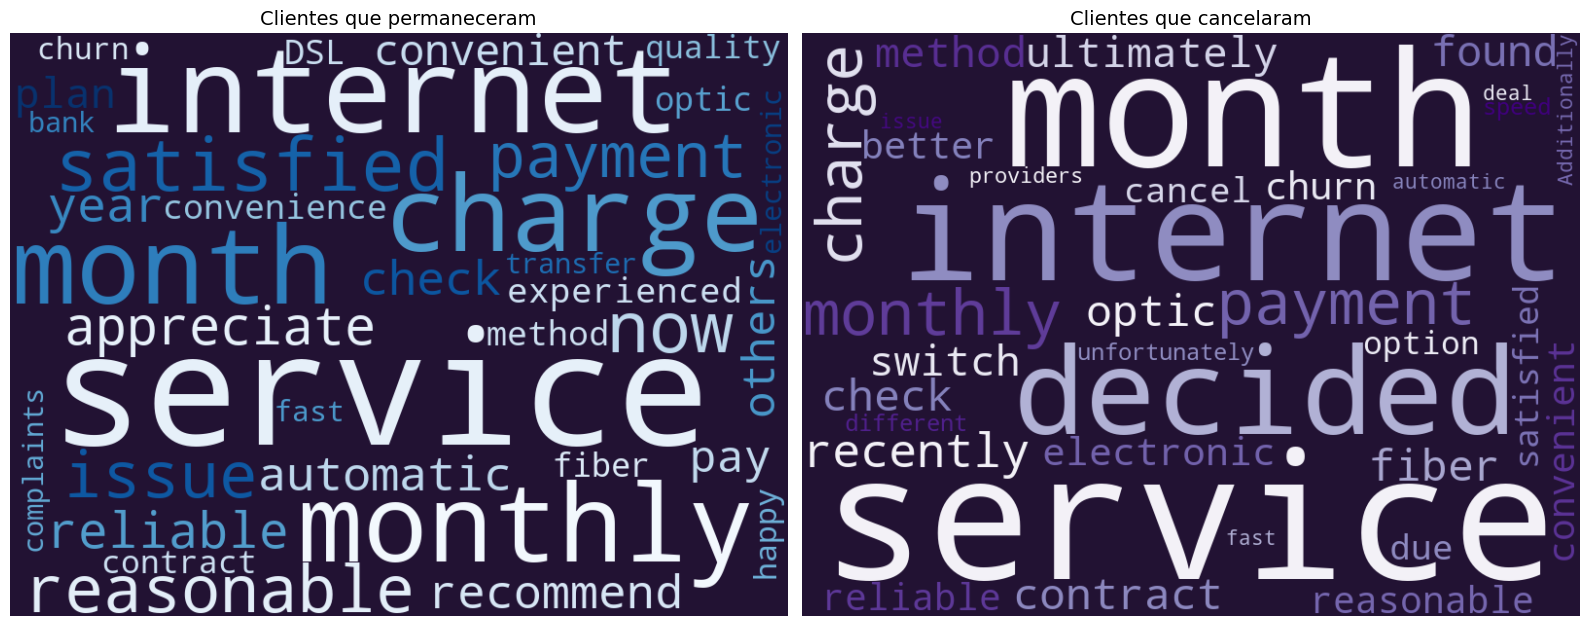

In [29]:
try:
    palavras_ignoradas = set(STOPWORDS)
    palavras_ignoradas.update({"customer", "customers", "company", "provider", "overall", "experience", "also", "really"})

    texto_nao_cancelou = " ".join(
        df_gold.loc[df_gold["Cancelamento"].eq("No"), "FeedbackCliente"].dropna().astype(str)
    )
    texto_cancelou = " ".join(
        df_gold.loc[df_gold["Cancelamento"].eq("Yes"), "FeedbackCliente"].dropna().astype(str)
    )

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    for ax, texto, titulo, mapa in [
        (axes[0], texto_nao_cancelou, "Clientes que permaneceram", "Blues"),
        (axes[1], texto_cancelou, "Clientes que cancelaram", "Purples"),
    ]:
        if texto.strip():
            nuvem = WordCloud(width=800, height=600, background_color="#221233", stopwords=palavras_ignoradas,
                              max_words=35, collocations=False, colormap=mapa, random_state=42).generate(texto)
            ax.imshow(nuvem, interpolation="bilinear")
            ax.set_title(titulo, fontsize=14)
        else:
            ax.text(0.5, 0.5, "Sem comentários disponíveis", ha="center", va="center")
        ax.axis("off")
    plt.tight_layout()
    plt.show()
except ImportError:
    print("Biblioteca wordcloud não instalada. Instale com: pip install wordcloud")

## 9. Síntese dos resultados e respostas às perguntas de negócio

1) Taxa geral de churn: 26.7% (1,504 de 5,634 clientes).
2) Modalidade contratual com maior taxa: Month-to-month (42.7%; n=3,099).
3) Faixa de permanência com maior taxa: 0-12 meses (46.8%; n=1,751).
4) Método de pagamento com maior taxa: Electronic check (45.1%; n=1,888).
5) Serviço de internet com maior taxa: Fiber optic (42.1%; n=2,477).
6) Cobrança mensal média, não cancelou: 60.96; cancelou: 74.63.
7) Renda mensal média, não cancelou: 5082.03; cancelou: 5167.63.

### Possíveis recomendações para a Terra Signal
1. Desenvolver acompanhamento preventivo para clientes nos primeiros 12 meses, especialmente nos grupos com taxas mais elevadas.
2. Revisar a proposta de valor e a comunicação dos planos com mensalidades elevadas, oferecendo opções adequadas ao perfil de uso.
3. Investigar a experiência dos clientes que utilizam cheque eletrônico, verificando etapas de pagamento, falhas e conveniência.
4. Avaliar programas de fidelização e benefícios para migração voluntária para contratos de maior duração, sem impor barreiras ao cancelamento.
5. Investigar reclamações e comentários dos clientes para relacionar motivos textuais com serviços, cobrança e suporte.

As recomendações são hipóteses de ação derivadas da análise descritiva. A efetividade deve ser avaliada por testes controlados ou acompanhamento de indicadores após a implantação.

## 10. Exportação das tabelas

In [ ]:
PASTA_DADOS = Path("arquitetura_dados")
PASTA_DADOS.mkdir(exist_ok=True)

tabelas_gold = {
    "clientes_csl.csv": df_bronze,
    "clientes_tgt.csv": df_silver,
    "clientes_ddm.csv": df_gold
}

for nome_arquivo, tabela in tabelas_gold.items():
    tabela.to_csv(PASTA_DADOS / nome_arquivo, index=False, encoding="utf-8-sig")

print(f"{len(tabelas_gold)} arquivos exportados para: {PASTA_DADOS.resolve()}")

3 arquivos Gold exportados para: C:\Users\giova\OneDrive\Documentos\PII2_databricks\arquitetura_dados
